# Part 4 — Singular value decomposition

From TOML-MIRI *Linear Algebra for Data Science* — exploration exercises (sheet section [4]).

Topic exercises:

- **4.1** Rotate, stretch, rotate
- **4.2** SVD vs eigendecomposition
- **4.3** Low-rank approximation of an image
- **4.4** Sum of rank-1 pieces

This notebook implements exercises **4.1**–**4.4**. Each exercise keeps the sheet's own parts — **Task**, **Explore**, **Explain** — and every identity carries a one-line np.allclose check.

## Setup

Shared imports and helpers for the whole notebook. A 2×2 matrix is decomposed as A = UΣVᵀ with the singular values in descending order. `decompose(A)` returns U, s, V, Vᵀ and Σ = diag(s); `stages(A)` returns the four point sets of the sheet's picture — x, Vᵀx, ΣVᵀx, UΣVᵀx — for x on the unit circle; and `plot_stages(A)` draws them with v₁, v₂ and their images σᵢuᵢ marked. All four panels of one matrix share the same axis limits, so lengths can be compared directly across them.

In [1]:
import numpy as np
import scipy
import ipywidgets as widgets
from IPython.display import display

import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

TOL = 1e-12


def unit_circle(n=2001):
    """n points of the unit circle, as columns of a 2 x n array."""
    t = np.linspace(0.0, 2.0 * np.pi, n)
    return np.vstack([np.cos(t), np.sin(t)])


def decompose(A):
    """SVD of a 2x2 matrix: A = U diag(s) V^T, singular values descending."""
    U, s, Vt = np.linalg.svd(A)
    V = Vt.T
    return U, s, V, Vt, np.diag(s)


def rank_of(s):
    """Numerical rank from the singular values."""
    return int(np.sum(s > TOL * max(1.0, float(s[0]))))


def condition_number(s):
    """sigma_max / sigma_min, or inf when sigma_min is numerically zero."""
    return float(s[0] / s[1]) if rank_of(s) == 2 else np.inf


def low_rank(M, k):
    """Best rank-k approximation of M: the first k terms of its SVD."""
    U, s, Vt = np.linalg.svd(M, full_matrices=False)
    return (U[:, :k] * s[:k]) @ Vt[:k]


def stages(A, n=2001):
    """x, V^T x, Sigma V^T x, U Sigma V^T x for x on the unit circle."""
    U, s, V, Vt, Sigma = decompose(A)
    X = unit_circle(n)
    X1 = Vt @ X
    X2 = Sigma @ X1
    X3 = U @ X2
    return X, X1, X2, X3


def plot_stages(A, ax=None, n=2001, title=None):
    """Four panels of the rotate-stretch-rotate picture, shared axis limits."""
    U, s, V, Vt, Sigma = decompose(A)
    X, X1, X2, X3 = stages(A, n)

    own = ax is None
    if own:
        fig, ax = plt.subplots(1, 4, figsize=(18, 4.7))
    else:
        fig = ax[0].figure

    lim = 1.18 * max(1.0, float(s[0]))
    ref = unit_circle(361)
    titles = ("1.  x", "2.  Vᵀx", "3.  ΣVᵀx", "4.  UΣVᵀx = Ax")
    labels = (("v₁", "v₂"),
              ("Vᵀv₁ = e₁", "Vᵀv₂ = e₂"),
              ("σ₁e₁", "σ₂e₂"),
              ("Av₁ = σ₁u₁", "Av₂ = σ₂u₂"))
    colors = ("royalblue", "crimson")

    for a, name, P in zip(ax, titles, (X, X1, X2, X3)):
        a.plot(ref[0], ref[1], ls="--", lw=0.9, color="0.75", zorder=1)
        a.plot(P[0], P[1], lw=2.2, color="black", zorder=2)
        a.set_aspect("equal")
        a.set_xlim(-lim, lim)
        a.set_ylim(-lim, lim)
        a.axhline(0.0, color="0.88", lw=0.8, zorder=0)
        a.axvline(0.0, color="0.88", lw=0.8, zorder=0)
        a.set_title(name)
        a.set_xlabel("y₁")
        a.set_ylabel("y₂")

    arrows = ((V[:, 0], V[:, 1]),
              (Vt @ V[:, 0], Vt @ V[:, 1]),
              (Sigma @ Vt @ V[:, 0], Sigma @ Vt @ V[:, 1]),
              (U @ Sigma @ Vt @ V[:, 0], U @ Sigma @ Vt @ V[:, 1]))
    for a, pair, (lab1, lab2) in zip(ax, arrows, labels):
        for w, color, lab in ((pair[0], colors[0], lab1), (pair[1], colors[1], lab2)):
            if np.linalg.norm(w) > 1e-12:
                a.annotate("", xy=w, xytext=(0.0, 0.0),
                           arrowprops=dict(arrowstyle="-|>", color=color, lw=2.0,
                                           shrinkA=0.0, shrinkB=0.0, mutation_scale=13))
                a.text(1.06 * w[0], 1.06 * w[1], lab, color=color, fontsize=10,
                       ha="left" if w[0] >= 0 else "right",
                       va="bottom" if w[1] >= 0 else "top")
            else:
                a.plot([0.0], [0.0], marker="o", ms=5, color=color)
                a.text(0.06, 0.06, lab + " = 0", color=color, fontsize=9)

    if own:
        if title is not None:
            fig.suptitle(title, y=1.02)
        fig.tight_layout()
    return fig, ax


print("numpy", np.__version__, "| scipy", scipy.__version__, "| ipywidgets", widgets.__version__)
print("decompose(), stages() and plot_stages() ready")

numpy 2.5.4 | scipy 1.18.1 | ipywidgets 8.1.9
decompose(), stages() and plot_stages() ready


## 4.1 — Rotate, stretch, rotate

### Task

Take a 2×2 matrix, compute A = UΣVᵀ, and draw the unit circle and its image in four panels:

    x,    Vᵀx,    ΣVᵀx,    UΣVᵀx = Ax

with v₁, v₂ marked in the first and Avᵢ = σᵢuᵢ in the last. The default is

    A = [ 1  2 ]
        [ 0  2 ]

from Example 4.3, with the four entries on sliders in the last cell. The dashed circle is the unit circle kept as a reference, and all panels share their axis limits.

In [2]:
# --- Task: Example 4.3, the factors and the numbers behind the panels -----
A41 = np.array([[1.0, 2.0],
                [0.0, 2.0]])

U, s, V, Vt, Sigma = decompose(A41)
X, X1, X2, X3 = stages(A41)

print("U ="); print(U)
print("sigma =", s)
print("V^T ="); print(Vt)
print("det = %+.4f = sigma1 sigma2 = %.4f" % (np.linalg.det(A41), s[0] * s[1]))
print("rank = %d   ||A||_2 = %.4f   kappa = %.4f"
      % (rank_of(s), s[0], condition_number(s)))
print("A v1 =", A41 @ V[:, 0], "  sigma1 u1 =", s[0] * U[:, 0])
print("A v2 =", A41 @ V[:, 1], "  sigma2 u2 =", s[1] * U[:, 1])

# the extreme stretches, sampled on a very fine unit circle
theta = np.linspace(0.0, 2.0 * np.pi, 200001)
stretch = np.linalg.norm(A41 @ np.vstack([np.cos(theta), np.sin(theta)]), axis=0)
print("max ||Ax|| = %.6f (sigma_max)   min ||Ax|| = %.6f (sigma_min)"
      % (stretch.max(), stretch.min()))

print("--- checks ---")
checks = {
    "U orthogonal": np.allclose(U.T @ U, np.eye(2)),
    "V orthogonal": np.allclose(V.T @ V, np.eye(2)),
    "A = U Sigma V^T": np.allclose(A41, U @ Sigma @ Vt),
    "A v_i = sigma_i u_i": np.allclose(A41 @ V, U * s),
    "U Sigma V^T x = A x": np.allclose(X3, A41 @ X),
    "image is the ellipse": np.allclose(
        ((U.T @ X3)[0] / s[0]) ** 2 + ((U.T @ X3)[1] / s[1]) ** 2, 1.0),
    "area = pi sigma1 sigma2": np.allclose(
        np.pi * s[0] * s[1], np.pi * abs(np.linalg.det(A41))),
    "max stretch = sigma_max": np.allclose(stretch.max(), s[0]),
    "min stretch = sigma_min": np.allclose(stretch.min(), s[1]),
    "kappa = cond(A)": np.allclose(condition_number(s), np.linalg.cond(A41)),
}
for name, ok in checks.items():
    print("%-24s %s" % (name, ok))

U =
[[ 0.7497 -0.6618]
 [ 0.6618  0.7497]]
sigma = [2.9208 0.6847]
V^T =
[[ 0.2567  0.9665]
 [-0.9665  0.2567]]
det = +2.0000 = sigma1 sigma2 = 2.0000
rank = 2   ||A||_2 = 2.9208   kappa = 4.2656
A v1 = [2.1897 1.933 ]   sigma1 u1 = [2.1897 1.933 ]
A v2 = [-0.4532  0.5133]   sigma2 u2 = [-0.4532  0.5133]
max ||Ax|| = 2.920810 (sigma_max)   min ||Ax|| = 0.684742 (sigma_min)
--- checks ---
U orthogonal             True
V orthogonal             True
A = U Sigma V^T          True
A v_i = sigma_i u_i      True
U Sigma V^T x = A x      True
image is the ellipse     True
area = pi sigma1 sigma2  True
max stretch = sigma_max  True
min stretch = sigma_min  True
kappa = cond(A)          True


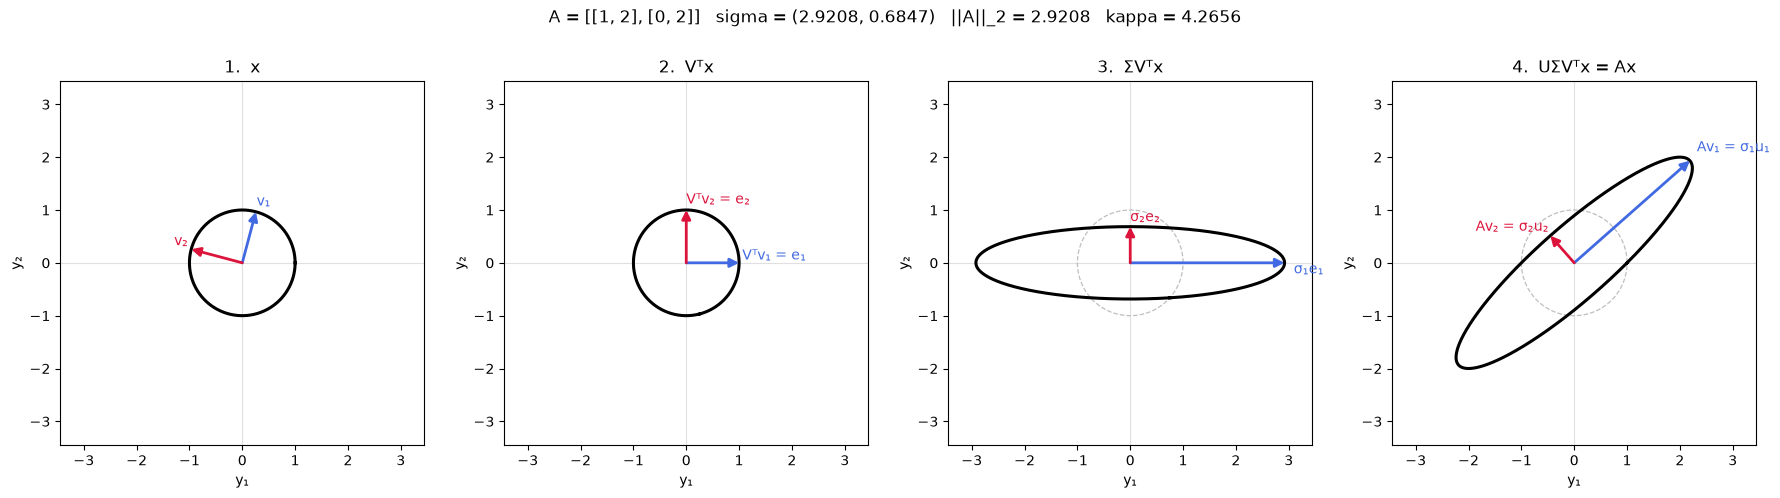

In [3]:
# --- Task: the four panels for the Example 4.3 matrix ---------------------
fig, _ = plot_stages(
    A41, n=2001,
    title="A = [[1, 2], [0, 2]]   sigma = (%.4f, %.4f)   ||A||_2 = %.4f   kappa = %.4f"
          % (s[0], s[1], s[0], condition_number(s)))
plt.show()

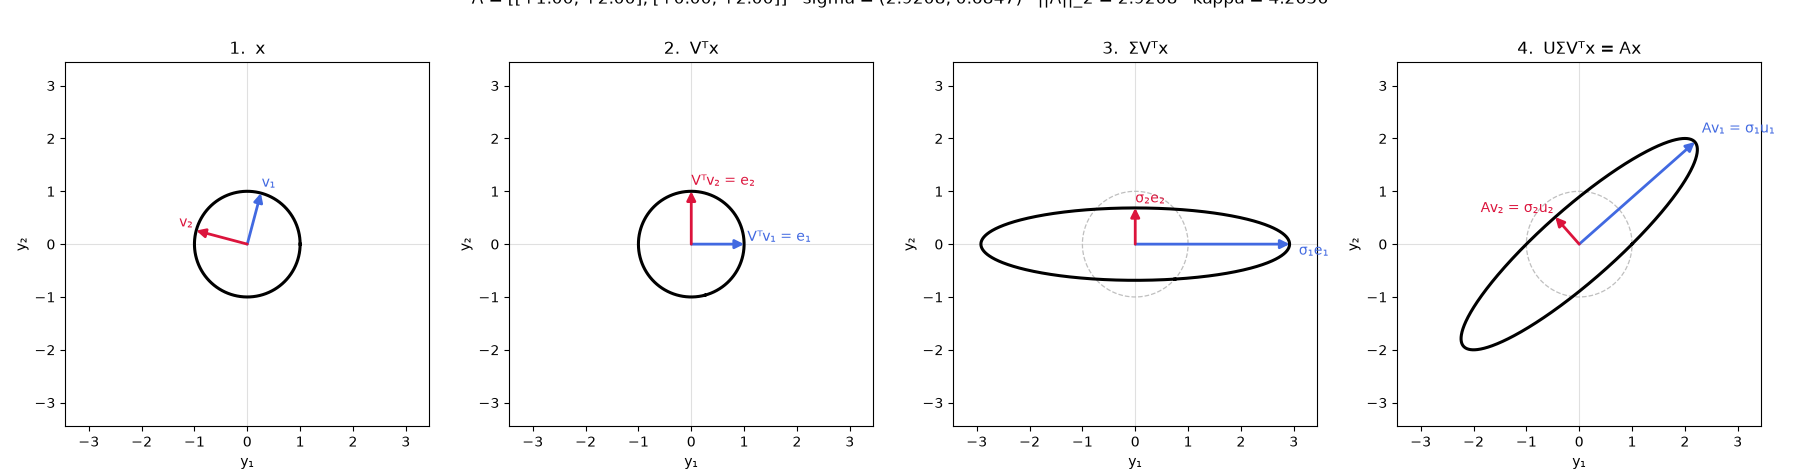

In [4]:
# --- Task: the four panels with the four entries on sliders ---------------
# Read-out and figure are shown once and then replaced with update_display_data,
# so nothing is cleared and the cell does not blink while a slider moves.
import io

from IPython.display import HTML, Image as IPyImage

SLIDER = dict(min=-3.0, max=3.0, step=0.1, continuous_update=True,
              layout=widgets.Layout(width="230px"),
              style={"description_width": "34px"})
a11 = widgets.FloatSlider(value=1.0, description="a11", **SLIDER)
a12 = widgets.FloatSlider(value=2.0, description="a12", **SLIDER)
a21 = widgets.FloatSlider(value=0.0, description="a21", **SLIDER)
a22 = widgets.FloatSlider(value=2.0, description="a22", **SLIDER)
controls = {"a11": a11, "a12": a12, "a21": a21, "a22": a22}
_handles = {}


def show(key, obj):
    """Display obj once, then update that same output in place."""
    if key in _handles:
        _handles[key].update(obj)
    else:
        _handles[key] = display(obj, display_id="4.1 " + key)


def refresh(*_):
    A = np.array([[a11.value, a12.value],
                  [a21.value, a22.value]])
    _, sw, Vw, _, _ = decompose(A)
    kap = condition_number(sw)
    kap_s = ("%.4f" % kap) if np.isfinite(kap) else "inf"
    show("readout", HTML(
        "<pre>A = [[%+.2f, %+.2f], [%+.2f, %+.2f]]\n"
        "sigma = (%.4f, %.4f)   kappa = %s   det = %+.4f   rank = %d\n"
        "v1 = (%+.3f, %+.3f)   v2 = (%+.3f, %+.3f)</pre>"
        % (*A.ravel(), sw[0], sw[1], kap_s, np.linalg.det(A), rank_of(sw),
           Vw[0, 0], Vw[1, 0], Vw[0, 1], Vw[1, 1])))
    figw, _ = plot_stages(
        A, n=721,
        title="A = [[%+.2f, %+.2f], [%+.2f, %+.2f]]   sigma = (%.4f, %.4f)   ||A||_2 = %.4f   kappa = %s"
              % (*A.ravel(), sw[0], sw[1], sw[0], kap_s))
    buf = io.BytesIO()
    figw.savefig(buf, format="png")
    plt.close(figw)
    show("panels", IPyImage(data=buf.getvalue(), format="png"))


display(widgets.VBox([widgets.HTML("<b>Matrix entries</b>"),
                      widgets.HBox([a11, a12]),
                      widgets.HBox([a21, a22]),
                      widgets.HTML("<i>dashed grey: unit circle (reference)</i>")]))
for w in controls.values():
    w.observe(refresh, names="value")
refresh()

### Explore

Two more matrices next to Example 4.3 — a singular one, and an orthogonal rotation by 30°:

    A_sing = [ 1    2 ]      R(30°) = [ cos 30°  −sin 30° ]
             [ 0.5  1 ]               [ sin 30°   cos 30° ]

The table gives σ, rank, ||A||₂ and κ, and the figure repeats the four stages for each matrix.

In [5]:
# --- Explore: Example 4.3, a singular matrix and an orthogonal matrix -----
t30 = np.radians(30.0)
R30 = np.array([[np.cos(t30), -np.sin(t30)],
                [np.sin(t30),  np.cos(t30)]])
CASES = [("Example 4.3", A41),
         ("singular", np.array([[1.0, 2.0], [0.5, 1.0]])),
         ("orthogonal R(30°)", R30)]

print("%-19s %8s %8s %4s %8s %8s %8s"
      % ("case", "sigma_1", "sigma_2", "rank", "||A||_2", "kappa", "det"))
for name, M in CASES:
    _, sm, _, _, _ = decompose(M)
    kap = condition_number(sm)
    print("%-19s %8.4f %8.4f %4d %8.4f %8s %+8.4f"
          % (name, sm[0], sm[1], rank_of(sm), sm[0],
             ("%.4f" % kap) if np.isfinite(kap) else "inf", np.linalg.det(M)))

print("--- checks ---")
for name, M in CASES:
    Um, sm, Vm, Vtm, Sm = decompose(M)
    _, _, _, Xm3 = stages(M)
    checks = {
        "A = U Sigma V^T": np.allclose(M, Um @ Sm @ Vtm),
        "A v_i = sigma_i u_i": np.allclose(M @ Vm, Um * sm),
        "U, V orthogonal": np.allclose(Um.T @ Um, np.eye(2))
                           and np.allclose(Vm.T @ Vm, np.eye(2)),
        "area = pi sigma1 sigma2": np.allclose(
            np.pi * sm[0] * sm[1], np.pi * abs(np.linalg.det(M))),
    }
    if rank_of(sm) == 2:
        checks["kappa = cond(A)"] = np.allclose(condition_number(sm), np.linalg.cond(M))
    if rank_of(sm) == 1:
        checks["image is a segment"] = np.linalg.matrix_rank(Xm3) == 1
    if name.startswith("orthogonal"):
        checks["sigma_1 = sigma_2 = 1"] = np.allclose(sm, [1.0, 1.0])
    print("%-19s %s" % (name, {k: bool(v) for k, v in checks.items()}))

case                 sigma_1  sigma_2 rank  ||A||_2    kappa      det
Example 4.3           2.9208   0.6847    2   2.9208   4.2656  +2.0000
singular              2.5000   0.0000    1   2.5000      inf  +0.0000
orthogonal R(30°)     1.0000   1.0000    2   1.0000   1.0000  +1.0000
--- checks ---
Example 4.3         {'A = U Sigma V^T': True, 'A v_i = sigma_i u_i': True, 'U, V orthogonal': True, 'area = pi sigma1 sigma2': True, 'kappa = cond(A)': True}
singular            {'A = U Sigma V^T': True, 'A v_i = sigma_i u_i': True, 'U, V orthogonal': True, 'area = pi sigma1 sigma2': True, 'image is a segment': True}
orthogonal R(30°)   {'A = U Sigma V^T': True, 'A v_i = sigma_i u_i': True, 'U, V orthogonal': True, 'area = pi sigma1 sigma2': True, 'kappa = cond(A)': True, 'sigma_1 = sigma_2 = 1': True}


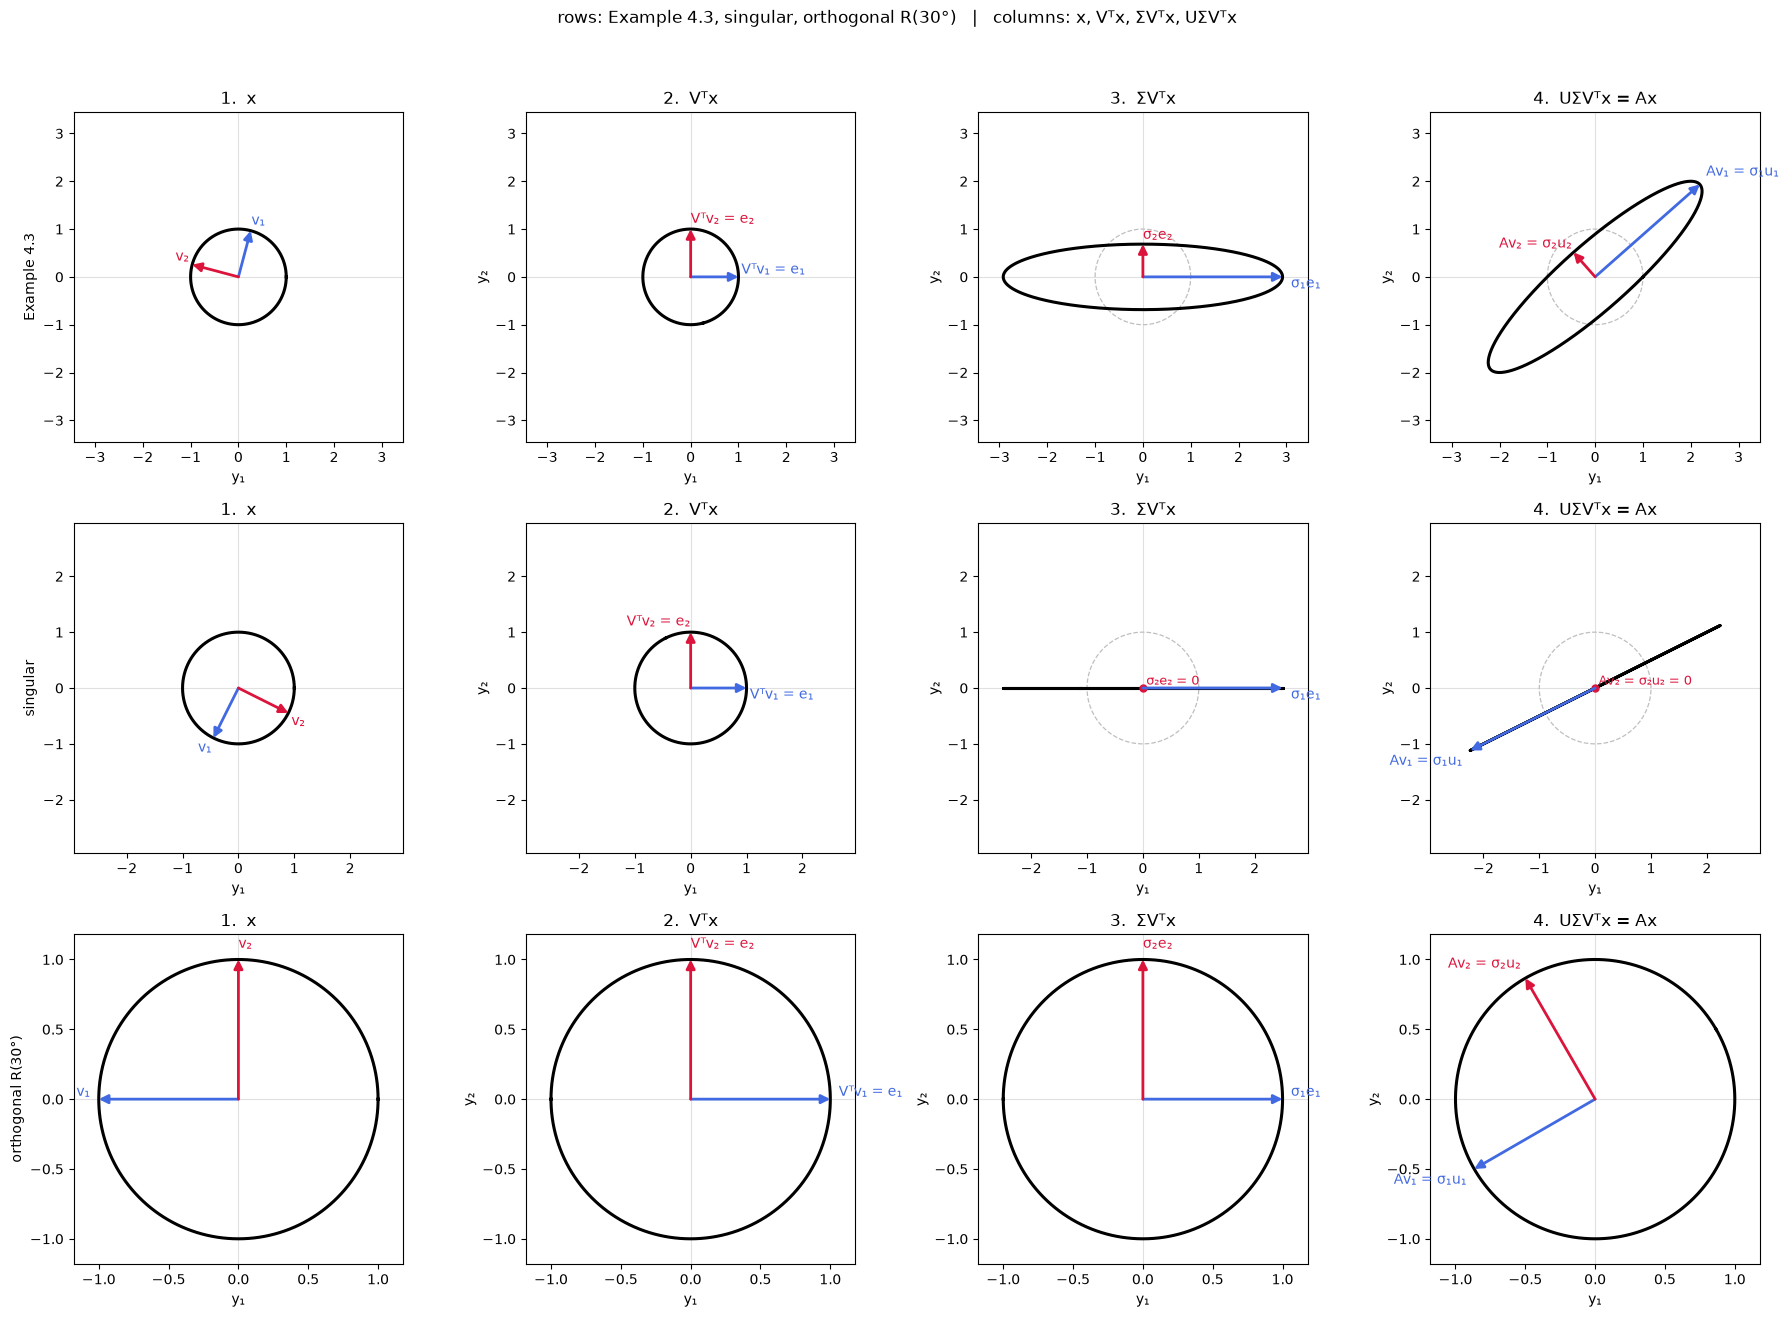

In [6]:
# --- Explore: the four stages for each of the three matrices --------------
fig, axes = plt.subplots(3, 4, figsize=(18, 13.2))
for i, (name, M) in enumerate(CASES):
    plot_stages(M, ax=axes[i], n=1001)
    axes[i, 0].set_ylabel(name, fontsize=10)
fig.suptitle("rows: Example 4.3, singular, orthogonal R(30°)   |   columns: x, Vᵀx, ΣVᵀx, UΣVᵀx",
             y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Explain

**Where the singular values sit.** The panels apply the factors of A = UΣVᵀ from the right. Vᵀ is orthogonal, so panel 2 is the circle again, with v₁, v₂ sent to e₁, e₂. In that frame Σ scales the two coordinates by σ₁ and σ₂, giving an axis-aligned ellipse whose semi-axes are σ₁ and σ₂. U is orthogonal as well and only turns or reflects it, so panel 4 is Ax with the same semi-axes, and the arrows are Avᵢ = σᵢuᵢ.

**Spectral norm.** ||A||₂ = max over ||x|| = 1 of ||Ax||₂ is the longest semi-axis of the image ellipse, that is σmax: for A = [[1, 2], [0, 2]] it is 2.9208, the same value the scan over 200001 directions reaches. It is also the radius of the smallest origin-centred circle that contains the ellipse.

**Condition number.** κ(A) = σmax/σmin = 4.2656 here is the ratio of the longest to the shortest semi-axis. It is unchanged by turning or reflecting A, or by scaling it, and κ = 1 exactly when the image is a circle, as for an orthogonal A with σ₁ = σ₂ = 1. A singular A has σmin = 0: the ellipse collapses to a segment, κ = ∞, and there is no inverse.

**Reading it for Ax = b.** Because κ(A) = ||A||₂ ||A⁻¹||₂, a relative error in b can be amplified by at most κ in x, and worst along the short axis, where the ellipse is thin and x moves a lot for a small change in b. A flat ellipse is an ill-conditioned system, a circle is a perfectly conditioned one, a segment has no solution map at all.

## 4.2 — SVD vs eigendecomposition

### Task

For the 3×2 matrix of Example 4.1,

    A = [ 2  1 ]
        [ 3  0 ]
        [ 1  3 ]

compute the SVD and the eigendecompositions of AᵀA (2×2) and AAᵀ (3×3), and match them:

    AᵀA = V ΣᵀΣ Vᵀ,    AAᵀ = U ΣΣᵀ Uᵀ,    σᵢ² = λᵢ

eigh returns λ ascending and svd returns σ descending, so compare the columns after reversing them, and up to sign.

In [7]:
# --- Task: Example 4.1, the SVD and the two eigenproblems ----------------
A42 = np.array([[2.0, 1.0],
                [3.0, 0.0],
                [1.0, 3.0]])

U, s, Vt = np.linalg.svd(A42)
V = Vt.T
G, H = A42.T @ A42, A42 @ A42.T
lamG, QG = np.linalg.eigh(G)                 # ascending
lamH, QH = np.linalg.eigh(H)
lamH = np.where(np.abs(lamH) < TOL, 0.0, lamH)   # the zero eigenvalue, exactly
V_ev, U_ev = QG[:, ::-1], QH[:, ::-1]            # descending, same order as s

Sig = np.zeros((3, 2))
Sig[:2, :2] = np.diag(s)

print("sigma         =", s)
print("lambda(A^T A) =", lamG[::-1], " sqrt =", np.sqrt(lamG[::-1]))
print("lambda(A A^T) =", lamH[::-1], " sqrt =", np.sqrt(lamH[::-1]))
print("\nV (svd) =\n", V, "\nV (eigh A^T A) =\n", V_ev)
print("U (svd) =\n", U, "\nU (eigh A A^T) =\n", U_ev)

print("\nsigns matching eigh to svd: V", np.sign(np.sum(V * V_ev, axis=0)),
      " U", np.sign(np.sum(U * U_ev, axis=0)))
at_u3 = A42.T @ U[:, 2]                       # A^T u3 = 0 to rounding
print("left null vector u3 =", U[:, 2], "   A^T u3 =", np.where(np.abs(at_u3) < TOL, 0.0, at_u3))

# the signs are free: flip u_i and v_i together, A stays the same
Uf, Vf = U * np.array([1.0, -1.0, 1.0]), V * np.array([1.0, -1.0])

print("\n--- checks ---")
checks = {
    "A = U Sigma V^T": np.allclose(A42, U @ Sig @ Vt),
    "U^T U = I_3": np.allclose(U.T @ U, np.eye(3)),
    "V^T V = I_2": np.allclose(V.T @ V, np.eye(2)),
    "A^T A = V Sigma^T Sigma V^T": np.allclose(G, V @ (Sig.T @ Sig) @ V.T),
    "A A^T = U Sigma Sigma^T U^T": np.allclose(H, U @ (Sig @ Sig.T) @ U.T),
    "A^T A = V_ev diag(lambda) V_ev^T": np.allclose(G, V_ev @ np.diag(lamG[::-1]) @ V_ev.T),
    "A A^T = U_ev diag(lambda) U_ev^T": np.allclose(H, U_ev @ np.diag(lamH[::-1]) @ U_ev.T),
    "sigma_i^2 = lambda_i": np.allclose(np.append(s ** 2, 0.0), lamH[::-1]),
    "eigh ascending": np.allclose(lamG, np.sort(lamG)),
    "V = eigvecs of A^T A up to sign": np.allclose(np.abs(V), np.abs(V_ev)),
    "U = eigvecs of A A^T up to sign": np.allclose(np.abs(U), np.abs(U_ev)),
    "A^T u3 = 0 (left null space)": np.allclose(A42.T @ U[:, 2], 0.0),
    "rank A = 2 nonzero sigma": rank_of(s) == 2 and int(np.sum(lamH > TOL)) == 2,
    "flipping u_i and v_i keeps A": np.allclose(Uf @ Sig @ Vf.T, A42),
}
for name, ok in checks.items():
    print("%-34s %s" % (name, ok))

sigma         = [4.1696 2.5719]
lambda(A^T A) = [17.3852  6.6148]  sqrt = [4.1696 2.5719]
lambda(A A^T) = [17.3852  6.6148  0.    ]  sqrt = [4.1696 2.5719 0.    ]

V (svd) =
 [[-0.8281 -0.5606]
 [-0.5606  0.8281]] 
V (eigh A^T A) =
 [[-0.8281  0.5606]
 [-0.5606 -0.8281]]
U (svd) =
 [[-0.5317 -0.114  -0.8393]
 [-0.5958 -0.6539  0.4663]
 [-0.602   0.7479  0.2798]] 
U (eigh A A^T) =
 [[ 0.5317  0.114   0.8393]
 [ 0.5958  0.6539 -0.4663]
 [ 0.602  -0.7479 -0.2798]]

signs matching eigh to svd: V [ 1. -1.]  U [-1. -1. -1.]
left null vector u3 = [-0.8393  0.4663  0.2798]    A^T u3 = [0. 0.]

--- checks ---
A = U Sigma V^T                    True
U^T U = I_3                        True
V^T V = I_2                        True
A^T A = V Sigma^T Sigma V^T        True
A A^T = U Sigma Sigma^T U^T        True
A^T A = V_ev diag(lambda) V_ev^T   True
A A^T = U_ev diag(lambda) U_ev^T   True
sigma_i^2 = lambda_i               True
eigh ascending                     True
V = eigvecs of A^T A up to sign 

### Explain

**Matching.** AᵀA and AAᵀ are symmetric, and their nonzero eigenvalues are the squares of the singular values: 17.3852 and 6.6148, so σ = 4.1696 and 2.5719. AᵀA = VΣᵀΣVᵀ makes V the eigenvector matrix of AᵀA, and AAᵀ = UΣΣᵀUᵀ makes the first two columns of U the eigenvectors of AAᵀ. eigh returns λ ascending and svd returns σ descending, so the columns are reversed before comparing; the two then agree entry by entry up to sign — eigh puts V's second column, and all three columns of U, at the opposite sign from svd.

**The extra zero.** AAᵀ is 3×3 but rank(AAᵀ) = rank(A) = 2, so one of its eigenvalues is 0. Its eigenvector u₃ satisfies ‖Aᵀu₃‖² = u₃ᵀAAᵀu₃ = 0, hence Aᵀu₃ = 0: the zero eigenspace of AAᵀ is exactly the left null space, here the line through (−0.8393, 0.4663, 0.2798). In general AᵀA has n − r zero eigenvalues and AAᵀ has m − r; this A is tall with full column rank, so the 2×2 has none and the 3×3 has one.

**Uniqueness.** The pair (uᵢ, vᵢ) is determined only up to a common sign: (−uᵢ, −vᵢ) leaves σᵢuᵢvᵢᵀ, and therefore A, unchanged, and the flip check still rebuilds A while U and V themselves change. A repeated singular value allows any rotation inside its subspace, and a zero singular value any orthonormal basis of the null space; here the σ's are distinct and the left null space is a line, so the only freedom is that sign.

## 4.3 — Low-rank approximation of an image

### Task

Load the grayscale Grace Hopper photograph that ships with Matplotlib (`grace_hopper.jpg`, no download) as a 600 × 512 matrix A with entries in [0, 1], and compute its SVD. Plot the singular values on a log scale and show A next to the rank-k approximations

    Aₖ = σ₁u₁v₁ᵀ + ⋯ + σₖuₖvₖᵀ

for k = 1, 5, 20, 50, 100. Print the Eckart–Young errors σₖ₊₁ and √(Σᵢ₌ₖ₊₁ⁿ σᵢ²) beside the measured 2-norm and Frobenius errors.

image (600, 512) | rank 512 | sigma_1 = 192.07, sigma_min = 7.53e-03
  k   sigma_k+1  ||A-Ak||_2  ||A-Ak||_F    rel. F
  1     49.9816     49.9816    116.4472    0.5184
  5     26.9113     26.9113     77.8213    0.3465
 20      9.7200      9.7200     43.0964    0.1919
 50      4.0512      4.0512     24.4824    0.1090
100      1.9212      1.9212     14.0219    0.0624

--- checks ---
A = U diag(s) V^T                    True
U^T U = I and V^T V = I              True
sigma descending                     True
sum sigma^2 = ||A||_F^2              True
rank(A_k) = k                        True
Eckart-Young 2-norm = sigma_{k+1}    True
Eckart-Young Frobenius = tail        True


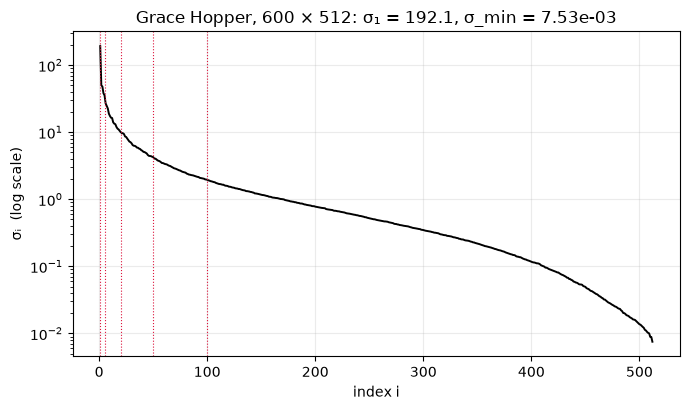

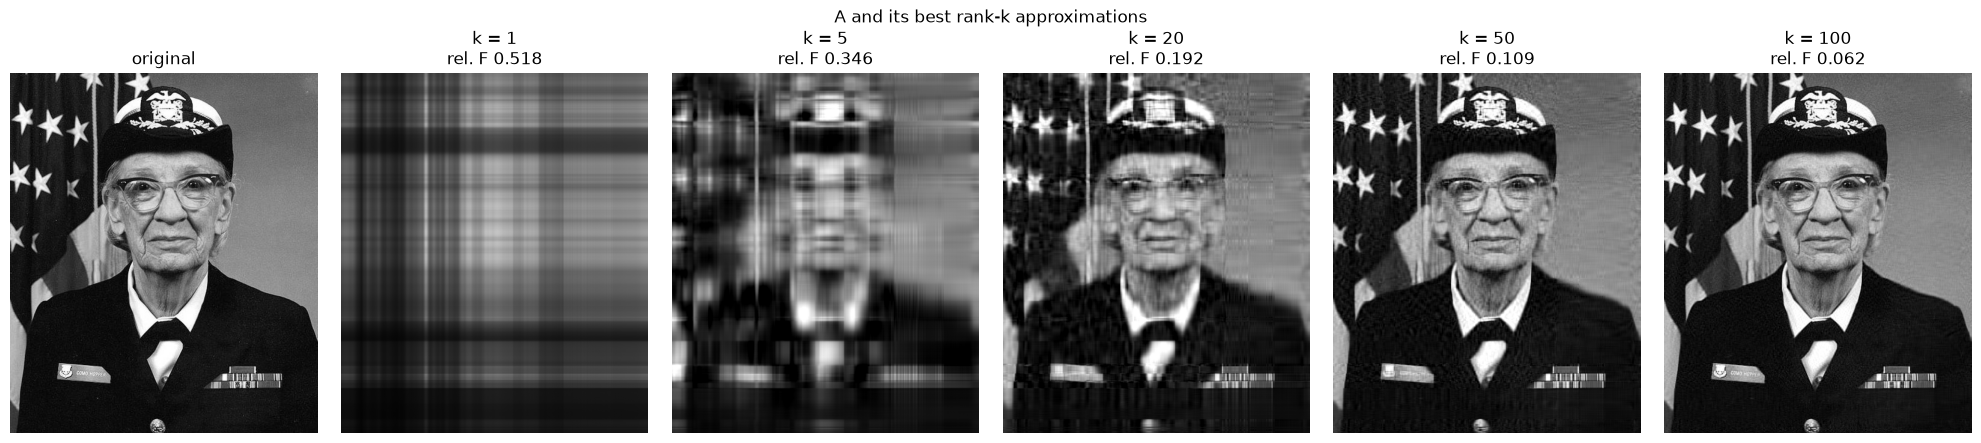

In [8]:
# --- Task: the Grace Hopper photograph as a grayscale matrix ----------------
rgb = plt.imread(matplotlib.cbook.get_sample_data("grace_hopper.jpg"))
A43 = (rgb[..., :3] @ np.array([0.299, 0.587, 0.114])) / 255.0
U, s, Vt = np.linalg.svd(A43, full_matrices=False)
ks = (1, 5, 20, 50, 100)

A_ks = {k: low_rank(A43, k) for k in ks}
e2 = {k: np.linalg.norm(A43 - A_ks[k], 2) for k in ks}
eF = {k: np.linalg.norm(A43 - A_ks[k], "fro") for k in ks}
tail = {k: np.sqrt(np.sum(s[k:] ** 2)) for k in ks}
relF = {k: eF[k] / np.linalg.norm(A43, "fro") for k in ks}
rank = int(np.sum(s > TOL * s[0]))

print("image", A43.shape, "| rank", rank,
      "| sigma_1 = %.2f, sigma_min = %.2e" % (s[0], s[-1]))
print("%3s  %10s  %10s  %10s  %8s" % ("k", "sigma_k+1", "||A-Ak||_2", "||A-Ak||_F", "rel. F"))
for k in ks:
    print("%3d  %10.4f  %10.4f  %10.4f  %8.4f" % (k, s[k], e2[k], eF[k], relF[k]))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(np.arange(1, s.size + 1), s, lw=1.4, color="black")
for k in ks:
    ax.axvline(k, color="crimson", lw=0.8, ls=":")
ax.set_xlabel("index i")
ax.set_ylabel("σᵢ  (log scale)")
ax.set_title(f"Grace Hopper, {A43.shape[0]} × {A43.shape[1]}: "
             f"σ₁ = {s[0]:.1f}, σ_min = {s[-1]:.2e}")
ax.grid(alpha=0.25)
fig.tight_layout()

panels = [("original", A43, None)] + [(f"k = {k}", A_ks[k], relF[k]) for k in ks]
fig, axes = plt.subplots(1, 6, figsize=(20, 4.3))
for ax, (name, img, rel) in zip(axes, panels):
    ax.imshow(img, cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(name if rel is None else f"{name}\nrel. F {rel:.3f}")
    ax.axis("off")
fig.suptitle("A and its best rank-k approximations", y=1.02)
fig.tight_layout()

print("\n--- checks ---")
checks = {
    "A = U diag(s) V^T": np.allclose(A43, (U * s) @ Vt),
    "U^T U = I and V^T V = I": (np.allclose(U.T @ U, np.eye(s.size))
                               and np.allclose(Vt @ Vt.T, np.eye(s.size))),
    "sigma descending": np.all(s[:-1] >= s[1:]),
    "sum sigma^2 = ||A||_F^2": np.allclose(np.sum(s ** 2), np.linalg.norm(A43, "fro") ** 2),
    "rank(A_k) = k": all(np.linalg.matrix_rank(A_ks[k]) == k for k in ks),
    "Eckart-Young 2-norm = sigma_{k+1}": all(np.allclose(e2[k], s[k]) for k in ks),
    "Eckart-Young Frobenius = tail": all(np.allclose(eF[k], tail[k]) for k in ks),
}
for name, ok in checks.items():
    print("%-36s %s" % (name, ok))

### Explore

Repeat the spectrum and the relative error ‖A − Aₖ‖_F/‖A‖_F for three 600 × 512 images: the photograph, a 16-pixel checkerboard, and zero-mean Gaussian noise. Print each numerical rank, the relative error at k = 20 and k = 100, and the energy kept at k = 20.

image         rank rel.F k=20 rel.F k=100 energy k=20
photo          512      0.192      0.062      0.963
checkerboard     2      0.000      0.000      1.000
noise          512      0.933      0.708      0.129

--- checks ---
checkerboard rank 2                  True
checkerboard exact at k=2            True
photo full rank 512                  True
noise full rank 512                  True
energy = sum of sigma^2              True


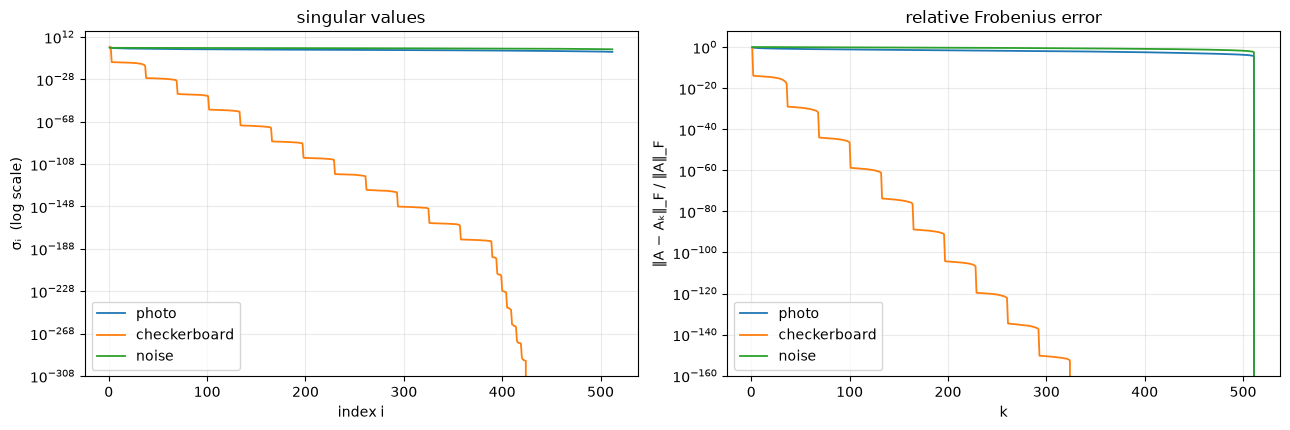

In [9]:
# --- Explore: photograph, checkerboard, zero-mean noise --------------------
ii, jj = np.indices(A43.shape)
images = {
    "photo": A43,
    "checkerboard": ((ii // 16 + jj // 16) % 2).astype(float),
    "noise": np.random.default_rng(0).standard_normal(A43.shape),
}
svds = {name: np.linalg.svd(img, compute_uv=False) for name, img in images.items()}
norms = {name: np.linalg.norm(img, "fro") for name, img in images.items()}
rel = {name: np.sqrt(np.append(np.cumsum(sv[::-1] ** 2)[::-1], 0.0)) / norms[name]
       for name, sv in svds.items()}

print("%-12s %5s %10s %10s %10s" % ("image", "rank", "rel.F k=20", "rel.F k=100", "energy k=20"))
for name, sv in svds.items():
    r = int(np.sum(sv > TOL * sv[0]))
    print("%-12s %5d %10.3f %10.3f %10.3f"
          % (name, r, rel[name][20], rel[name][100], 1.0 - rel[name][20] ** 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for name, sv in svds.items():
    axes[0].semilogy(np.arange(1, sv.size + 1), sv, lw=1.3, label=name)
axes[0].set_xlabel("index i")
axes[0].set_ylabel("σᵢ  (log scale)")
axes[0].set_title("singular values")
axes[0].legend()
axes[0].grid(alpha=0.25)

kk = np.arange(1, A43.shape[1] + 1)
for name in images:
    axes[1].semilogy(kk, rel[name][1:], lw=1.3, label=name)
axes[1].set_xlabel("k")
axes[1].set_ylabel("‖A − Aₖ‖_F / ‖A‖_F")
axes[1].set_title("relative Frobenius error")
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.tight_layout()

print("\n--- checks ---")
checks = {
    "checkerboard rank 2": int(np.sum(svds["checkerboard"] > TOL * svds["checkerboard"][0])) == 2,
    "checkerboard exact at k=2": np.allclose(low_rank(images["checkerboard"], 2), images["checkerboard"]),
    "photo full rank 512": int(np.sum(svds["photo"] > TOL * svds["photo"][0])) == 512,
    "noise full rank 512": int(np.sum(svds["noise"] > TOL * svds["noise"][0])) == 512,
    "energy = sum of sigma^2": all(np.allclose(np.sum(sv ** 2), norms[name] ** 2)
                                   for name, sv in svds.items()),
}
for name, ok in checks.items():
    print("%-36s %s" % (name, ok))

### Explain

**Eckart–Young.** The measured errors equal the Eckart–Young values to rounding: for k = 1, 5, 20, 50, 100, ‖A − Aₖ‖₂ = σₖ₊₁ = 49.98, 26.91, 9.72, 4.05, 1.92, while ‖A − Aₖ‖_F = √(Σᵢ₌ₖ₊₁ⁿ σᵢ²) = 116.45, 77.82, 43.10, 24.48, 14.02. The residual is the sum of the discarded rank-1 terms and is itself an SVD, so its largest singular value is exactly σₖ₊₁ and its squared Frobenius norm is the sum of the discarded σᵢ². For any B of rank at most k, B maps the (k+1)-dimensional span{v₁, …, vₖ₊₁} to a space of dimension at most k, so some unit z = Σᵢ₌₁ᵏ⁺¹ cᵢvᵢ lies in its null space; then ‖A − B‖₂ ≥ ‖(A − B)z‖ = ‖Az‖ = √(Σᵢ₌₁ᵏ⁺¹ σᵢ²cᵢ²) ≥ σₖ₊₁, and the Eckart–Young theorem gives the same optimality for the Frobenius norm.

**Which compresses best.** The checkerboard is exactly rank 2 — whether a pixel is black depends only on ⌊i/16⌋ + ⌊j/16⌋ mod 2, so the matrix is the sum of two rank-1 patterns — and A₂ = A: it wins trivially, storing 2(600 + 512 + 1) = 2 226 numbers instead of 307 200. The photograph is full rank, but it is smooth: its spectrum falls 4.4 decades, so A₂₀ already keeps 96.3% of the Frobenius energy in 20(600 + 512 + 1) = 22 260 numbers (7.2% of the matrix), and A₁₀₀ keeps 99.6%. Noise has independent pixels, so its spectrum is flat through the bulk (σ₁/‖A‖_F = 0.084) and A₁₀₀ keeps only 49.9%: there is no low-rank structure to exploit. Order: checkerboard, photograph, noise.

## 4.4 — Sum of rank-1 pieces

### Task

Using the 3×4 matrix of Example 4.6,

    A = [ 2  1  0  1 ]
        [ 1  3  4  2 ]
        [ 0  1  3  3 ]

compute its SVD and plot each rank-1 term

    Tₖ = σₖ uₖ vₖᵀ

as a heatmap, with the running sums A₁ = T₁, A₂ = T₁ + T₂, A₃ = T₁ + T₂ + T₃. Print the singular values, the residual after each term, and the three Schatten norms of Example 4.4:

    ‖A‖₂ = σ₁,    ‖A‖_F = √(Σₖ σₖ²),    ‖A‖_N = Σₖ σₖ.

The heatmaps share one diverging colour scale, so a term and the running sum can be compared entry by entry.

sigma = 6.9092  2.2380  1.5015
  k   sigma_k  ||T_k||_F   ||A-A_k||_2   ||A-A_k||_F  energy kept
  1    6.9092    6.9092        2.2380        2.6950      86.79%
  2    2.2380    2.2380        1.5015        1.5015      95.90%
  3    1.5015    1.5015        0.0000        0.0000     100.00%
||A||_2 = 6.9092   ||A||_F = 7.4162   ||A||_N = 10.6486

--- checks ---
A = T1 + T2 + T3                 True
each T_k has rank 1              True
T_i orthogonal to T_j (i < j)    True
||T_k||_F = sigma_k              True
A_k = first k terms              True
A_3 = A                          True
||A||_2 = sigma_1                True
||A||_F = sqrt(sum sigma_k^2)    True
||A||_N = sum sigma_k            True
||A||_F = sqrt(tr(A^T A))        True
Example 4.4 norms                True
Eckart-Young at k = 2            True


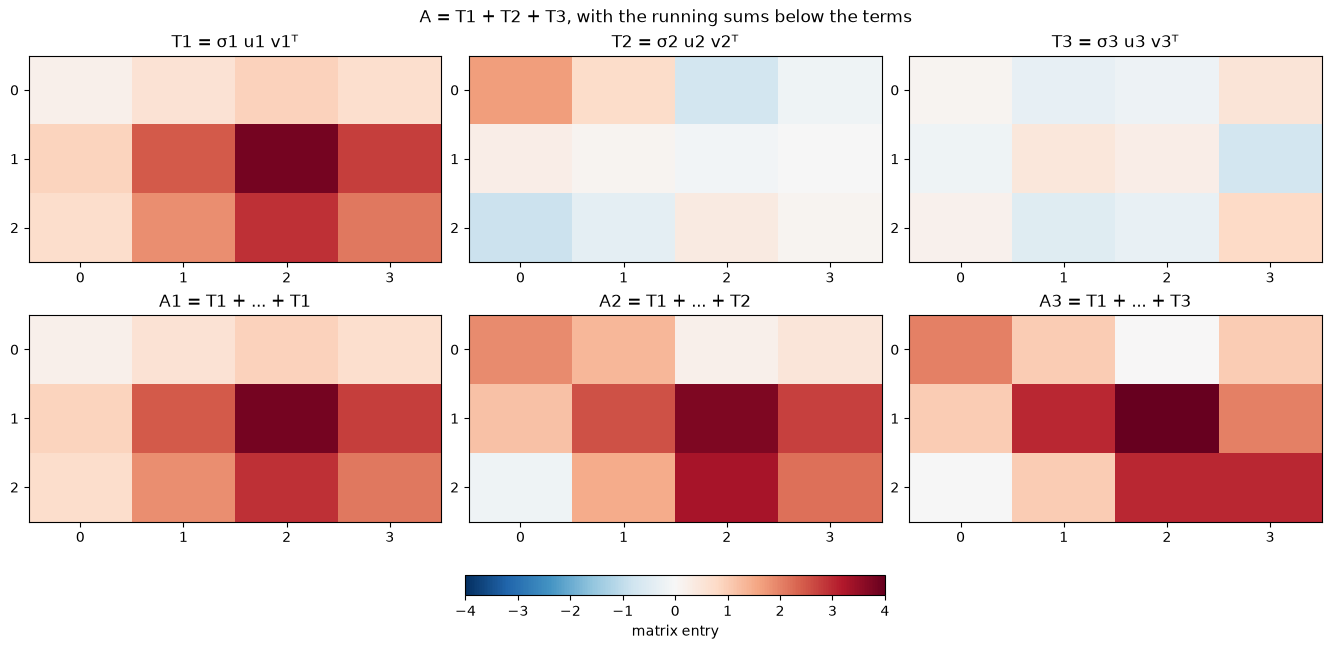

In [10]:
# --- Task: the rank-1 pieces of Example 4.6 and their running sums ---------
A44 = np.array([[2.0, 1.0, 0.0, 1.0],
                [1.0, 3.0, 4.0, 2.0],
                [0.0, 1.0, 3.0, 3.0]])

U44, s44, Vt44 = np.linalg.svd(A44, full_matrices=False)
terms = [s44[k] * np.outer(U44[:, k], Vt44[k]) for k in range(3)]
partial = np.cumsum(terms, axis=0)
schatten = {"spectral": s44[0],
            "Frobenius": np.sqrt(np.sum(s44 ** 2)),
            "nuclear": np.sum(s44)}

print("sigma =", "  ".join("%.4f" % v for v in s44))
print("%3s  %8s  %8s  %12s  %12s  %10s"
      % ("k", "sigma_k", "||T_k||_F", "||A-A_k||_2", "||A-A_k||_F", "energy kept"))
for k in range(3):
    print("%3d  %8.4f  %8.4f  %12.4f  %12.4f  %9.2f%%"
          % (k + 1, s44[k], np.linalg.norm(terms[k]),
             np.linalg.norm(A44 - partial[k], 2),
             np.linalg.norm(A44 - partial[k], "fro"),
             100.0 * np.sum(s44[:k + 1] ** 2) / np.sum(s44 ** 2)))
print("||A||_2 = %.4f   ||A||_F = %.4f   ||A||_N = %.4f"
      % (schatten["spectral"], schatten["Frobenius"], schatten["nuclear"]))

lim = max(np.abs(A44).max(), max(np.abs(T).max() for T in terms))
norm = matplotlib.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
cmap = plt.get_cmap("RdBu_r")

fig, axes = plt.subplots(2, 3, figsize=(13.2, 6.4), layout="constrained")
for k in range(3):
    for row, M, name in (
            (0, terms[k], "T%d = σ%d u%d v%dᵀ" % (k + 1, k + 1, k + 1, k + 1)),
            (1, partial[k], "A%d = T1 + ... + T%d" % (k + 1, k + 1))):
        ax = axes[row, k]
        im = ax.imshow(M, cmap=cmap, norm=norm, aspect="auto")
        ax.set_title(name)
        ax.set_xticks(range(4))
        ax.set_yticks(range(3))
fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.045, pad=0.06,
             label="matrix entry")
fig.suptitle("A = T1 + T2 + T3, with the running sums below the terms")

print("\n--- checks ---")
checks = {
    "A = T1 + T2 + T3": np.allclose(A44, sum(terms)),
    "each T_k has rank 1": all(np.linalg.matrix_rank(T) == 1 for T in terms),
    "T_i orthogonal to T_j (i < j)": np.allclose(
        [np.sum(terms[i] * terms[j]) for i in range(3) for j in range(i + 1, 3)], 0.0),
    "||T_k||_F = sigma_k": np.allclose([np.linalg.norm(T) for T in terms], s44),
    "A_k = first k terms": all(
        np.allclose(partial[k], sum(terms[:k + 1])) for k in range(3)),
    "A_3 = A": np.allclose(partial[2], A44),
    "||A||_2 = sigma_1": np.allclose(np.linalg.norm(A44, 2), s44[0]),
    "||A||_F = sqrt(sum sigma_k^2)": np.allclose(
        np.linalg.norm(A44, "fro"), np.sqrt(np.sum(s44 ** 2))),
    "||A||_N = sum sigma_k": np.allclose(
        np.linalg.norm(A44, "nuc"), np.sum(s44)),
    "||A||_F = sqrt(tr(A^T A))": np.allclose(
        np.linalg.norm(A44, "fro"), np.sqrt(np.trace(A44.T @ A44))),
    "Example 4.4 norms": np.allclose(
        list(schatten.values()), [6.909, 7.416, 10.648], atol=1e-3),
    "Eckart-Young at k = 2": np.allclose(
        np.linalg.norm(A44 - partial[1], 2), s44[2]),
}
for name, ok in checks.items():
    print("%-32s %s" % (name, ok))

### Explain

**What each piece adds.** Tₖ = σₖuₖvₖᵀ is rank 1: every column is a multiple of uₖ and every row is a multiple of vₖᵀ, so it carries one left direction and one right direction. Because the singular values are ordered and the terms are orthogonal under the Frobenius inner product, T₁ is the best rank-1 approximation of A (Eckart–Young) and already keeps σ₁²/Σσ² = 86.8% of ‖A‖_F²; here all its entries are positive. Adding T₂ removes the component along u₂v₂ᵀ, lowers the spectral residual to σ₃ = 1.5015 and raises the kept energy to 95.9%; T₃ is the signed remainder, and since A has rank 3 the running sum A₃ reproduces A. The residual after k terms is the tail Σᵢ₌ₖ₊₁ σᵢuᵢvᵢᵀ, whose largest singular value is σₖ₊₁, so each new term can only lower the error.

**The Schatten norms.** The three values are 6.9092, 7.4162 and 10.6486. The spectral norm is the largest singular value, the Frobenius norm is the Euclidean length of the vector (σ₁, σ₂, σ₃), and the nuclear norm is the sum of its entries. The checks verify all three against the singular values, and verify ‖A‖_F² = tr(AᵀA) = 55. For any matrix ‖A‖₂ ≤ ‖A‖_F ≤ ‖A‖_N, with equality throughout exactly when only one σ is nonzero; here the rank is 3, so both inequalities are strict (6.909 < 7.416 < 10.649). In the ellipsoid picture the σₖ are semi-axis lengths: the spectral norm is the longest semi-axis, the Frobenius norm is the length of the vector of semi-axes, and the nuclear norm is their sum. All three depend only on the singular values, so orthogonal changes of basis leave them unchanged.